# Modeling

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

In the EDA notebook, we added some columns to the dataset (hourly wind speed, log-transformed `pm2.5`, etc.). We will add them again here.

In [48]:
df = pd.read_csv("../data/PRSA_data.csv")

df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])

run_id = (df["cbwd"] != df["cbwd"].shift()).cumsum()
df["Iws_hourly"] = df.groupby(run_id)["Iws"].diff().fillna(df["Iws"])

df["log_pm"] = np.log1p(df["pm2.5"])

df.head()

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir,datetime,Iws_hourly,log_pm
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0,2010-01-01 00:00:00,1.79,NaN
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0,2010-01-01 01:00:00,3.13,NaN
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0,2010-01-01 02:00:00,1.79,NaN
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0,2010-01-01 03:00:00,3.13,NaN
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0,2010-01-01 04:00:00,3.13,NaN


## Addressing Missing Values (Again)

During EDA, we found several long stretches of missing data, along with some smaller ones. Let's interpolate data for gaps of 6 hours or less. Instead of running `interpolate(limit=6)` indiscriminately, we must restrict this to only the gaps of that size, otherwise it will fill in gaps of 6 hours within larger gaps.

In [49]:
is_missing = df["pm2.5"].isna().astype(int)
run_id = (is_missing != is_missing.shift()).cumsum()
run_len = is_missing.groupby(run_id).transform("sum")

short_gap = (is_missing == 1) & (run_len <= 6)

interpolated = df["pm2.5"].interpolate(method="linear")
df["pm2.5_filled"] = df["pm2.5"].where(~short_gap, interpolated)

df["pm2.5_filled"].isna().sum()

np.int64(1817)

Now we only have 1,817 missing values. We need to update the log-transformed `pm2.5` and convert the wind directions to numbers so that we can make the models:

In [50]:
df["log_pm"] = np.log1p(df["pm2.5_filled"])
df = pd.get_dummies(df, columns=["cbwd"], drop_first=True, dtype=int)
df.columns

Index(['No', 'year', 'month', 'day', 'hour', 'pm2.5', 'DEWP', 'TEMP', 'PRES',
       'Iws', 'Is', 'Ir', 'datetime', 'Iws_hourly', 'log_pm', 'pm2.5_filled',
       'cbwd_NW', 'cbwd_SE', 'cbwd_cv'],
      dtype='str')

## Train/Test Split

Since this is a time series, we'll train on the first four years (2010-2013) and test on the last one (2014) rather than doing a random split. We do this to avoid 2 consecutive hours falling in the training and test sets, which would lead the model to memorize data since hour-to-hour data is very similar (data leakage). Let's make the split:

In [51]:
model_df = df.dropna(subset=["log_pm"])

train = model_df[model_df["year"] <= 2013]
test = model_df[model_df["year"] == 2014]

features = ["DEWP", "TEMP", "PRES", "Iws_hourly", "Is", "Ir",
            "month", "hour", "cbwd_NW", "cbwd_SE", "cbwd_cv"]

X_train, y_train = train[features], train["log_pm"]
X_test, y_test = test[features], test["log_pm"]

print(X_train.shape, X_test.shape)

(33297, 11) (8710, 11)


1/5 years held out for testing means about an 80/20 split.

## Baseline/Linear Model

Let's see how the baseline and linear regression models do:

In [52]:
baseline_pred = np.full(len(y_test), y_train.mean())
print("Baseline RMSE:", np.sqrt(mean_squared_error(y_test, baseline_pred)))

lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
print("Train RMSE:", np.sqrt(mean_squared_error(y_train, lr.predict(X_train))))
print("Linear RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("Linear R2:", r2_score(y_test, lr_pred))

Baseline RMSE: 1.035353037543192
Train RMSE: 0.7521309495245522
Linear RMSE: 0.8187620537897475
Linear R2: 0.3737060605464205


### Assessment

The baseline prediction ("just predict the average y_train") has an RMSE of about 1.04. This is the number to beat. Simple linear regression does beat it, though not by much (RMSE about 0.82), and we see a very modest amount of overfitting with a training error of about 0.75. The `R2` score also leaves much to be desired (0.37), which we expect since the correlation table we made in EDA did not show any strong linear relationships with the features.

Let's implement a more flexible model.

## Random Forest

In [53]:
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                           random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("RF Train RMSE:", np.sqrt(mean_squared_error(y_train, rf.predict(X_train))))
print("RF RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("RF R2:", r2_score(y_test, rf_pred))

RF Train RMSE: 0.4015073436467752
RF RMSE: 0.680502619670707
RF R2: 0.5673642551275375


### Assessment

Before assessment, let's take a look at the features the forest thought were important:

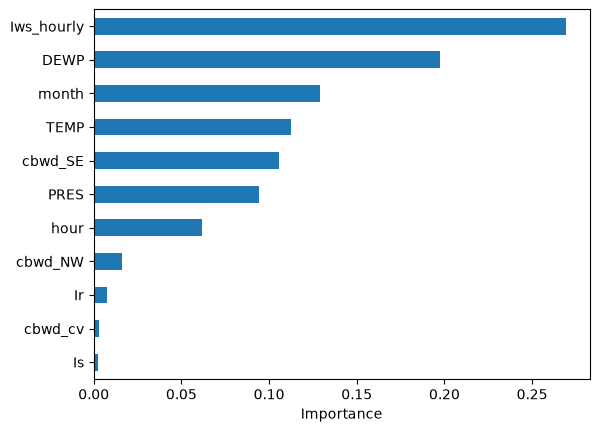

In [54]:
importances = pd.Series(rf.feature_importances_, index=features).sort_values()
importances.plot(kind="barh")
plt.xlabel("Importance")
plt.show()

The Random Forest test RMSE has dropped to ~0.68 and the `R2` score has increased to ~0.57, which is definitely an improvement.

Some expected results: wind speed, dewpoint, and month rank relatively high in importance. Wind direction seems to rank lower, but we expect it to appear lower on the importance rankings since we broke up the feature into each direction.

## Second Baseline Model: "Predict Previous Hour"

Let's observe a model that just predicts the previous pollution.

In [55]:
prev_hour = df["log_pm"].shift(1)
pair = pd.DataFrame({"y": df["log_pm"], "prev": prev_hour}).loc[test.index].dropna()
print("Baseline RMSE:", np.sqrt(mean_squared_error(pair["y"], pair["prev"])))

Baseline RMSE: 0.27092748839258207


Since weather/pollution changes slowly, we see that a model with access to previous-hour pollution performs much better than Random Forest, which makes sense. Let's try to find a model that can predict next-hour pollution better than this baseline, which will be much tougher to beat than our old baseline.

To do this, we will add two columns: one that provides the previous hour's pollution and one that provides the previous day's pollution at the same hour. Then we'll refit the baseline RMSE:

In [56]:
df["lag_1"] = df["log_pm"].shift(1)
df["lag_24"] = df["log_pm"].shift(24)

model_df = df.dropna(subset=["log_pm", "lag_1", "lag_24"])
train = model_df[model_df["year"] <= 2013]
test = model_df[model_df["year"] == 2014]

features2 = features + ["lag_1", "lag_24"]
X_train, y_train = train[features2], train["log_pm"]
X_test, y_test = test[features2], test["log_pm"]

print("Baseline RMSE:", np.sqrt(mean_squared_error(test["log_pm"], test["lag_1"])))

Baseline RMSE: 0.2704042605507539


It barely changed. Now we can refit the random forest with these new predictors:

In [57]:
rf2 = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                            random_state=42, n_jobs=-1)
rf2.fit(X_train, y_train)

print("RF2 Test RMSE:", np.sqrt(mean_squared_error(y_test, rf2.predict(X_test))))
print("RF2 Train RMSE:", np.sqrt(mean_squared_error(y_train, rf2.predict(X_train))))

RF2 Test RMSE: 0.2564080640665312
RF2 Train RMSE: 0.1867200092414279


### Assessment

While the model did perform better, it didn't by much. The weather features didn't really seem to add much and the random forest seems to have learned "copy the previous hour". Let's see how many hours the random forest outperformed the baseline on:

In [58]:
rf_err = (y_test - rf2.predict(X_test)).abs()
base_err = (y_test - X_test["lag_1"]).abs()
(rf_err < base_err).mean()

np.float64(0.5120739456961294)

We see that it's only  approximately a coin-flip against the baseline.

## Predicting Change in Pollution

### Change by Hour

To give the features a better chance, let's predict something else: "How much did log pollution change since the previous hour?"

In [59]:
rf3 = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                            random_state=42, n_jobs=-1)
rf3.fit(X_train, y_train - X_train["lag_1"])

pred3 = rf3.predict(X_test) + X_test["lag_1"]
print("Delta RF Test RMSE:", np.sqrt(mean_squared_error(y_test, pred3)))

Delta RF Test RMSE: 0.2517353364521647


### Assessment

There's a slight improvement, but not enough for it to be called a clear winner.

### Change by Day (24 hours)

Let's try a model that predicts the pollution level in 24 hours. A baseline "predict whatever the pollution is now" model should perform worse than the hourly one since there's more time passing now.

In [60]:
df["pm_now"] = df["log_pm"]
df["target_24"] = df["log_pm"].shift(-24)

model_df = df.dropna(subset=["target_24", "pm_now", "lag_1", "lag_24"])
train = model_df[model_df["year"] <= 2013]
test = model_df[model_df["year"] == 2014]

features3 = features2 + ["pm_now"]
X_train, y_train = train[features3], train["target_24"]
X_test, y_test = test[features3], test["target_24"]

print("Baseline RMSE:", np.sqrt(mean_squared_error(y_test, test["pm_now"])))

rf4 = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                            random_state=42, n_jobs=-1)
rf4.fit(X_train, y_train)
print("RF 24h Test RMSE:", np.sqrt(mean_squared_error(y_test, rf4.predict(X_test))))

Baseline RMSE: 1.1788837804995964
RF 24h Test RMSE: 0.9940522970795838


The "just predict the average pollution" RMSE actually does better than this baseline, which is rather poor. This makes sense since weather changes a lot in a day, so the "same as now" prediction becomes worse than just predicting whatever the average is. So we need to compare the model's Test RMSE to a fairer baseline, which is the training-mean baseline (except now it predicts pollution in 24 hours) for our new test rows:

In [61]:
mean_pred = np.full(len(y_test), y_train.mean())
print("Mean baseline RMSE:", np.sqrt(mean_squared_error(y_test, mean_pred)))

Mean baseline RMSE: 1.0361100524235776


### Assessment

The test RMSE barely beats the baseline. Making predictions that far in advance seems to be tricky for any model lacking future weather predictions. A likely reason is that the features only describe current conditions, while tomorrow’s pollution depends on weather the model can’t see. Weather forecasts as inputs would be the natural next step.

# Summary

The results of the analysis can be summarized as follows:

| Task | Baseline | Best model | Verdict |
| - | - | - | - |
| Estimate the *current* hour from current weather | 1.035 (mean) | 0.68 (RF) | clear win |
| Forecast 1 hour ahead | 0.270 (persistence baseline) | 0.252 (RF, predicting change) | roughly a tie |
| Forecast 24 hours ahead | 1.036 (mean baseline) | 0.994 (RF) | marginal |

## Limitations

1. For the 24-hour task, the target variable is pollution level in 24 hours. This means that the targets for the last day of 2013 (which is the last day of the training set) are actually from the next year (January 1 2014), meaning there is some overlap. At only 24 rows out of about 33,000, this is not a big deal.

2. For small gaps (6 hours or less) in the data, interpolated values were used. This means that the model gets to "see" a little bit in the future and cheat slightly for the forecasting models. That said, this only happens for 250 filled-in hours.

3. While there is a lot of hourly data, the test set only spans 1 year. Therefore, small changes in RMSE (e.g., from 0.270 to 0.252) may shift around for a different year.

4. Only observed weather was used; no forecasted weather.

5. The forests did not get tuned; this would be a natural possible next step.

# Thank you for Reading!

This project was a great way to practice machine learning techniques using real data. I certainly learned a lot, especially pandas tricks for time series datasets. Feel free to reach out on [LinkedIn](https://www.linkedin.com/in/hoswaymolina/) or otherwise for any comments or questions!